Dataset: (400, 4096)
Persons: 40
Training: (240, 4096)
Validation: (80, 4096)
Test: (80, 4096)


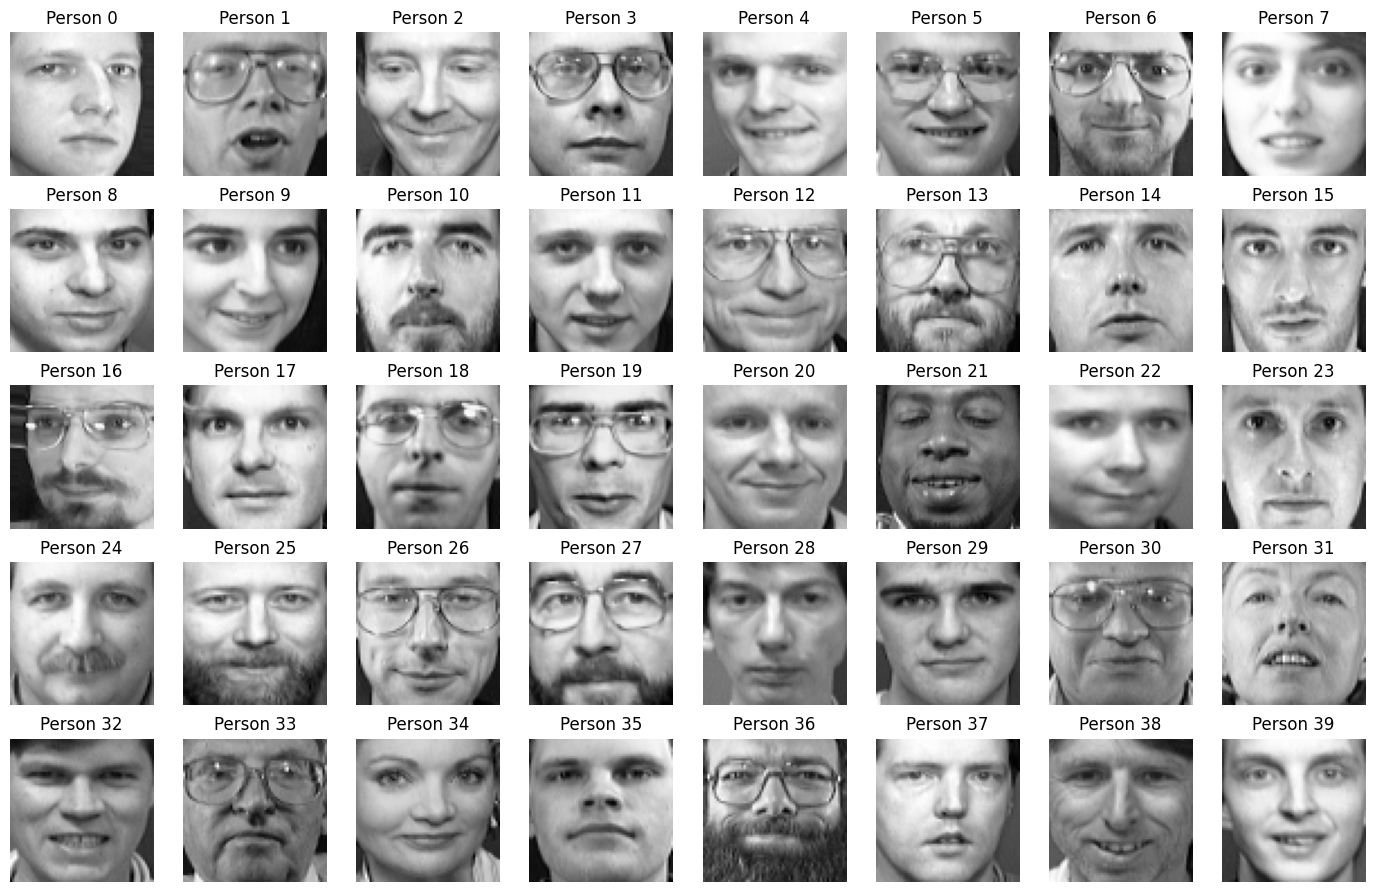


PART (a): SAMME TOY EXAMPLE
Initial weights: [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]
True labels: ['A' 'A' 'B' 'B' 'C' 'C']
Predictions: ['A' 'A' 'B' 'B' 'B' 'B']
Weighted error: 0.3333333333333333
Alpha: 1.3862943611198908
Updated weights: [0.08333333 0.08333333 0.08333333 0.08333333 0.33333333 0.33333333]
Weight sum: 1.0

PART (b): VALIDATION RESULTS
 depth  rounds  validation_accuracy
     4     100               0.3500
     3      50               0.3250
     4      50               0.3000
     4      25               0.2875
     2      50               0.2750
     3     100               0.2500
     3      25               0.2375
     2     100               0.1875
     2      25               0.1375
     4      10               0.1375
     1     100               0.1250
     2      10               0.0750
     3      10               0.0750
     1      25               0.0625
     1      50               0.0500
     1      10               0.0375

Sel

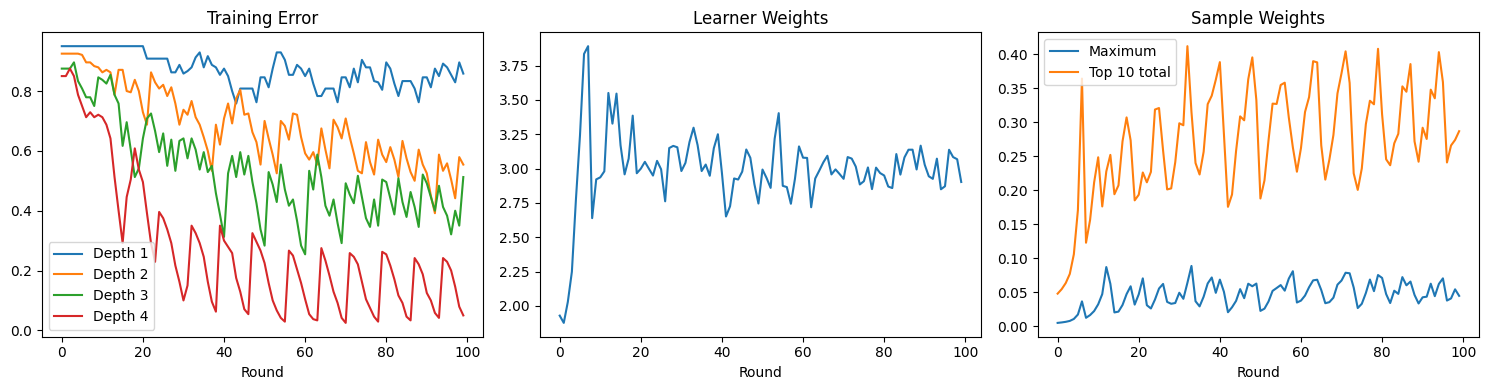


PART (c): BAGGING VS BOOSTING
   model  rounds      split  accuracy  training_time_seconds
Boosting      25      Train  0.604167              15.473568
Boosting      25 Validation  0.287500              15.473568
Boosting      25 Clean test  0.250000              15.473568
 Bagging      25      Train  0.454167              12.355786
 Bagging      25 Validation  0.237500              12.355786
 Bagging      25 Clean test  0.287500              12.355786
Boosting      50      Train  0.733333              31.163700
Boosting      50 Validation  0.300000              31.163700
Boosting      50 Clean test  0.312500              31.163700
 Bagging      50      Train  0.508333              24.688790
 Bagging      50 Validation  0.287500              24.688790
 Bagging      50 Clean test  0.350000              24.688790
Boosting     100      Train  0.950000              61.513310
Boosting     100 Validation  0.350000              61.513310
Boosting     100 Clean test  0.362500              61.

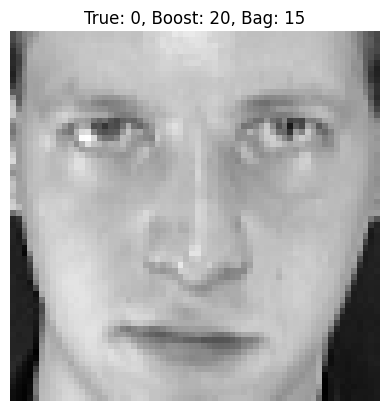


TRAINING FACE WITH HIGHEST BOOSTING WEIGHT
Training row: 126
True identity: 21
Final sample weight: 0.04454466025177938


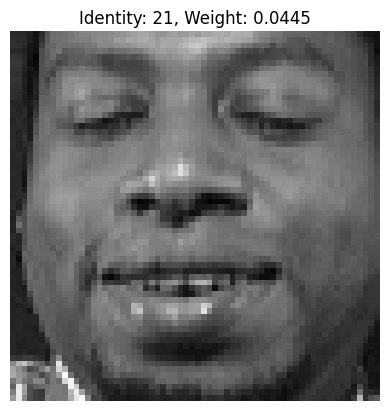

 round  prediction  correct  sample_weight
     1           0    False       0.004779
     2           0    False       0.005440
     3          21     True       0.000833
     4          21     True       0.000107
     5          21     True       0.000147
     6          21     True       0.000237
     7          21     True       0.000505
     8           0    False       0.001112
     9           0    False       0.001473
    10          21     True       0.000114
    11          21     True       0.000165
    12          21     True       0.000242
    13          21     True       0.000447
    14          21     True       0.000748
    15          21     True       0.001377
    16          21     True       0.002162
    17          21     True       0.003149
    18          21     True       0.000221
    19          21     True       0.000378
    20          21     True       0.000553
    21          21     True       0.000816
    22          21     True       0.001226
    23     

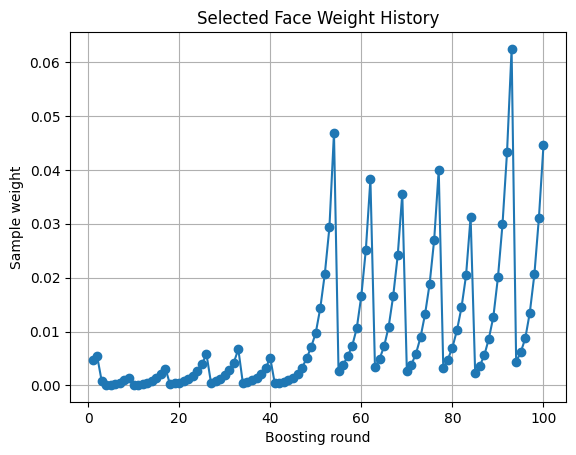


Q2 completed.


In [ ]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

ROLL_NUMBER = "p26cs0006"
SEED = int("".join(c for c in ROLL_NUMBER if c.isdigit()))
rng = np.random.default_rng(SEED)

try:
    data = fetch_olivetti_faces()
    images = data.images.astype(np.float32)
    X = data.data.astype(np.float32)
    y = data.target
except Exception:
    if not os.path.exists("olivettifaces.mat"):
        raise FileNotFoundError("Place olivettifaces.mat in the notebook folder.")
    faces = loadmat("olivettifaces.mat")["faces"].T.astype(np.float32)
    faces = (faces - faces.min()) / (faces.max() - faces.min())
    images = faces.reshape(400, 64, 64).transpose(0, 2, 1)
    X = images.reshape(400, 4096)
    y = np.arange(400) // 10

classes = np.unique(y)
K = len(classes)

train_idx, val_idx, test_idx = [], [], []

for c in classes:
    idx = rng.permutation(np.where(y == c)[0])
    train_idx.extend(idx[:6])
    val_idx.extend(idx[6:8])
    test_idx.extend(idx[8:10])

train_idx, val_idx, test_idx = map(
    np.array, (train_idx, val_idx, test_idx)
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

X_test_masked = X_test.reshape(-1, 64, 64).copy()
X_test_masked[:, 24:40, 24:40] = 0
X_test_masked = X_test_masked.reshape(-1, 4096)

print("Dataset:", X.shape)
print("Persons:", K)
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

fig, axes = plt.subplots(5, 8, figsize=(14, 9))
for c, ax in zip(classes, axes.flat):
    i = np.where(y_train == c)[0][0]
    ax.imshow(images[train_idx[i]], cmap="gray")
    ax.set_title(f"Person {c}")
    ax.axis("off")
plt.tight_layout()
plt.show()


toy_X = np.array([[0], [0.1], [1], [1.1], [2], [2.1]], dtype=float)
toy_y = np.array(["A", "A", "B", "B", "C", "C"])
toy_weights = np.ones(len(toy_y)) / len(toy_y)

toy_tree = DecisionTreeClassifier(max_depth=1, random_state=SEED)
toy_tree.fit(toy_X, toy_y, sample_weight=toy_weights)
toy_pred = toy_tree.predict(toy_X)
toy_error = np.sum(toy_weights * (toy_pred != toy_y))
toy_K = len(np.unique(toy_y))

print("\nPART (a): SAMME TOY EXAMPLE")
print("Initial weights:", toy_weights)
print("True labels:", toy_y)
print("Predictions:", toy_pred)
print("Weighted error:", toy_error)

if toy_error < 1 - 1 / toy_K:
    toy_alpha = np.log((1 - toy_error) / toy_error) + np.log(toy_K - 1)
    toy_weights *= np.exp(toy_alpha * (toy_pred != toy_y))
    toy_weights /= toy_weights.sum()
    print("Alpha:", toy_alpha)
    print("Updated weights:", toy_weights)
    print("Weight sum:", toy_weights.sum())
else:
    print("Weak learner is not better than random guessing.")


class SAMME:
    def __init__(self, rounds=100, depth=1, seed=0):
        self.rounds = rounds
        self.depth = depth
        self.seed = seed

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.K_ = len(self.classes_)
        self.trees_ = []
        self.alphas_ = []
        self.errors_ = []
        self.fit_times_ = []
        self.train_errors_ = []
        self.max_weights_ = []
        self.top10_weights_ = []
        self.weight_history_ = []

        n = len(y)
        w = np.ones(n) / n

        for t in range(self.rounds):
            tree = DecisionTreeClassifier(
                max_depth=self.depth,
                random_state=self.seed + t
            )

            start = time.perf_counter()
            tree.fit(X, y, sample_weight=w)
            self.fit_times_.append(time.perf_counter() - start)

            pred = tree.predict(X)
            err = np.sum(w * (pred != y))
            self.errors_.append(err)

            if err >= 1 - 1 / self.K_:
                self.fit_times_.pop()
                self.errors_.pop()
                break

            alpha = np.log(
                (1 - min(err, 1 - 1e-12)) / max(err, 1e-12)
            ) + np.log(self.K_ - 1)

            self.trees_.append(tree)
            self.alphas_.append(alpha)

            w *= np.exp(alpha * (pred != y))
            w /= w.sum()
            self.weight_history_.append(w.copy())
            self.max_weights_.append(w.max())
            self.top10_weights_.append(np.sort(w)[-10:].sum())

            self.train_errors_.append(
                np.mean(self.predict(X) != y)
            )

            if err < 1e-12:
                break

        self.alphas_ = np.array(self.alphas_)
        self.weight_history_ = np.array(self.weight_history_)
        return self

    def scores(self, X, rounds=None):
        n = len(self.trees_) if rounds is None else min(rounds, len(self.trees_))
        result = np.zeros((len(X), self.K_))

        for tree, alpha in zip(self.trees_[:n], self.alphas_[:n]):
            pred = tree.predict(X)
            for j, c in enumerate(self.classes_):
                result[:, j] += alpha * (pred == c)

        return result

    def predict(self, X, rounds=None):
        return self.classes_[np.argmax(self.scores(X, rounds), axis=1)]

    def confidence(self, X, rounds=None):
        s = self.scores(X, rounds)
        total = self.alphas_[:(
            len(self.trees_) if rounds is None
            else min(rounds, len(self.trees_))
        )].sum()
        return s.max(axis=1) / total if total > 0 else np.zeros(len(X))


depths = [1, 2, 3, 4]
round_options = [10, 25, 50, 100]
models = {}
results = []

for depth in depths:
    model = SAMME(100, depth, SEED).fit(X_train, y_train)
    models[depth] = model

    for rounds in round_options:
        if len(model.trees_) >= rounds:
            results.append({
                "depth": depth,
                "rounds": rounds,
                "validation_accuracy": accuracy_score(
                    y_val, model.predict(X_val, rounds)
                )
            })

results_df = pd.DataFrame(results)

if results_df.empty:
    raise RuntimeError("No valid boosting configuration was trained.")

results_df = results_df.sort_values(
    ["validation_accuracy", "depth", "rounds"],
    ascending=[False, True, True]
).reset_index(drop=True)

print("\nPART (b): VALIDATION RESULTS")
print(results_df.to_string(index=False))

best = results_df.iloc[0]
best_depth = int(best["depth"])
best_rounds = int(best["rounds"])
boost = models[best_depth]

print("\nSelected depth:", best_depth)
print("Selected rounds:", best_rounds)
print("Validation accuracy:", best["validation_accuracy"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for depth, model in models.items():
    axes[0].plot(model.train_errors_, label=f"Depth {depth}")
axes[0].set_title("Training Error")
axes[0].set_xlabel("Round")
axes[0].legend()

axes[1].plot(boost.alphas_)
axes[1].set_title("Learner Weights")
axes[1].set_xlabel("Round")

axes[2].plot(boost.max_weights_, label="Maximum")
axes[2].plot(boost.top10_weights_, label="Top 10 total")
axes[2].set_title("Sample Weights")
axes[2].set_xlabel("Round")
axes[2].legend()

plt.tight_layout()
plt.show()


def fit_bagging(X, y, depth, seed, rounds=100):
    rng_local = np.random.default_rng(seed)
    trees, fit_times = [], []
    n = len(y)

    for t in range(rounds):
        idx = rng_local.integers(0, n, size=n)
        tree = DecisionTreeClassifier(
            max_depth=depth, random_state=seed + t
        )
        start = time.perf_counter()
        tree.fit(X[idx], y[idx])
        fit_times.append(time.perf_counter() - start)
        trees.append(tree)

    return trees, fit_times


def bag_scores(trees, X, rounds=None):
    used = trees if rounds is None else trees[:rounds]
    s = np.zeros((len(X), K))

    for tree in used:
        pred = tree.predict(X)
        for j, c in enumerate(classes):
            s[:, j] += (pred == c)

    return s / len(used)


def bag_predict(trees, X, rounds=None):
    return classes[np.argmax(bag_scores(trees, X, rounds), axis=1)]


bag_trees, bag_times = fit_bagging(
    X_train, y_train, best_depth, SEED + 1000
)

single = DecisionTreeClassifier(
    max_depth=best_depth, random_state=SEED
)
start = time.perf_counter()
single.fit(X_train, y_train)
single_time = time.perf_counter() - start

comparison = []

for n in [25, 50, 100]:
    if n > len(boost.trees_):
        continue

    for name, predictor, elapsed in [
        (
            "Boosting",
            lambda x, n=n: boost.predict(x, n),
            sum(boost.fit_times_[:n])
        ),
        (
            "Bagging",
            lambda x, n=n: bag_predict(bag_trees, x, n),
            sum(bag_times[:n])
        )
    ]:
        for split, xx, yy in [
            ("Train", X_train, y_train),
            ("Validation", X_val, y_val),
            ("Clean test", X_test, y_test)
        ]:
            comparison.append({
                "model": name,
                "rounds": n,
                "split": split,
                "accuracy": accuracy_score(yy, predictor(xx)),
                "training_time_seconds": elapsed
            })

comparison_df = pd.DataFrame(comparison)
print("\nPART (c): BAGGING VS BOOSTING")
print(comparison_df.to_string(index=False))
print("Single tree training time:", single_time)


def tree_confidence(tree, X):
    return tree.predict_proba(X).max(axis=1)


def bag_confidence(trees, X, rounds=100):
    return bag_scores(trees, X, rounds).max(axis=1)


def boost_confidence(model, X, rounds):
    return model.confidence(X, rounds)


final_results = []

for split, xx, yy in [
    ("Clean test", X_test, y_test),
    ("Masked test", X_test_masked, y_test)
]:
    predictions = [
        ("Single tree", single.predict(xx), tree_confidence(single, xx)),
        ("Bagging", bag_predict(bag_trees, xx),
         bag_confidence(bag_trees, xx)),
        ("Boosting", boost.predict(xx, best_rounds),
         boost_confidence(boost, xx, best_rounds))
    ]

    for name, pred, conf in predictions:
        final_results.append({
            "test_set": split,
            "model": name,
            "accuracy": accuracy_score(yy, pred),
            "mean_winning_confidence": conf.mean()
        })

final_df = pd.DataFrame(final_results)
print("\nPART (d): CLEAN VS MASKED TEST")
print(final_df.to_string(index=False))


boost_pred = boost.predict(X_test, best_rounds)
bag_pred = bag_predict(bag_trees, X_test)
different = np.flatnonzero(boost_pred != bag_pred)

print("\nBOOSTING AND BAGGING DISAGREEMENT")

if len(different) == 0:
    print("No disagreement found.")
else:
    i = different[0]
    print("Test row:", i)
    print("True identity:", y_test[i])
    print("Boosting prediction:", boost_pred[i])
    print("Bagging prediction:", bag_pred[i])
    print("Boosting confidence:", boost_confidence(
        boost, X_test[i:i+1], best_rounds
    )[0])
    print("Bagging vote fraction:", bag_confidence(
        bag_trees, X_test[i:i+1]
    )[0])

    plt.imshow(images[test_idx[i]], cmap="gray")
    plt.title(
        f"True: {y_test[i]}, Boost: {boost_pred[i]}, Bag: {bag_pred[i]}"
    )
    plt.axis("off")
    plt.show()


print("\nTRAINING FACE WITH HIGHEST BOOSTING WEIGHT")

if len(boost.weight_history_) > 0:
    w = boost.weight_history_[-1]
    i = int(np.argmax(w))

    print("Training row:", i)
    print("True identity:", y_train[i])
    print("Final sample weight:", w[i])

    plt.imshow(images[train_idx[i]], cmap="gray")
    plt.title(f"Identity: {y_train[i]}, Weight: {w[i]:.4f}")
    plt.axis("off")
    plt.show()

    history = []
    for t in range(1, len(boost.trees_) + 1):
        p = boost.predict(X_train[i:i+1], t)[0]
        history.append({
            "round": t,
            "prediction": p,
            "correct": p == y_train[i],
            "sample_weight": boost.weight_history_[t-1, i]
        })

    print(pd.DataFrame(history).to_string(index=False))

    h = pd.DataFrame(history)
    plt.plot(h["round"], h["sample_weight"], marker="o")
    plt.xlabel("Boosting round")
    plt.ylabel("Sample weight")
    plt.title("Selected Face Weight History")
    plt.grid(True)
    plt.show()

